# Model A — authenticity (IBM AML)

Run after Model B. The account label is `y_auth=0` if the account appears in any laundering-labeled transaction, otherwise `1`. IBM AML is a synthetic multi-agent simulation dataset, so this model learns generator patterns; it is not validated on Indian MSME or UPI businesses. Transactions are aggregated to account-level features. We do not use generator/archetype flags, graph position, laundering-ring structure, protected attributes, or entity names. GST mismatch and verified rail count are deterministic policy handling, not model features.

The provided HI-Small transaction CSV is read in chunks. Its short date span limits history-based features.

In [ ]:
from pathlib import Path
import json, platform
from datetime import datetime,timezone
import numpy as np,pandas as pd,sklearn,joblib
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support,confusion_matrix,roc_auc_score,average_precision_score,balanced_accuracy_score
import matplotlib.pyplot as plt
SEED=42; SCHEMA='1.0'; ROOT=Path.cwd()
while not (ROOT/'IBM_AML').exists() and ROOT!=ROOT.parent: ROOT=ROOT.parent
DATA=ROOT/'IBM_AML'/'HI-Small_Trans.csv'; MODELS=ROOT/'models'; REPORTS=ROOT/'reports'
MODELS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
print('root',ROOT,'python',platform.python_version(),'pandas',pd.__version__,'sklearn',sklearn.__version__,'bytes',DATA.stat().st_size)

## Load HI-Small data in chunks and aggregate participant labels

Source contains two columns named Account; pandas calls them `Account` and `Account.1`. A laundering label marks both participants suspicious. Receiver credits are used for payer concentration and amount features; labels are aggregated across sender and receiver roles.

In [2]:
chunks=[]
for c in pd.read_csv(DATA,chunksize=400_000,low_memory=False):
    c['Timestamp']=pd.to_datetime(c['Timestamp'],errors='coerce')
    c['Is Laundering']=pd.to_numeric(c['Is Laundering'],errors='coerce').fillna(0).astype('int8')
    c['Amount Received']=pd.to_numeric(c['Amount Received'],errors='coerce')
    chunks.append(c)
tx=pd.concat(chunks,ignore_index=True)
print('rows',len(tx),'dates',tx.Timestamp.min(),tx.Timestamp.max(),'laundered transaction prevalence',tx['Is Laundering'].mean(),'positive transactions',int(tx['Is Laundering'].sum()))
print(tx.columns.tolist())

rows 5078345 dates 2022-09-01 00:00:00 2022-09-18 16:18:00 laundered transaction prevalence 0.0010194266045335635 positive transactions 5177
['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']


## Build the handoff's account-level features

Features: payer HHI, maximum payer share, round amount ratio, history weeks, and empty-then-spike. Amount divisibility uses documented units 100/500/1000 in source currency. Features are computed per account in its dominant receiving currency to avoid mixing currencies.

In [3]:
# Labels from both account roles; no graph/topology-derived feature is created.
suspicious=set(pd.concat([tx.loc[tx['Is Laundering'].eq(1),'Account'],tx.loc[tx['Is Laundering'].eq(1),'Account.1']]).dropna().astype(str))
recv=tx[['Timestamp','Account','Account.1','Amount Received','Receiving Currency','Is Laundering']].copy()
recv.columns=['ts','payer','account_id','amount','currency','laundering']
recv=recv.dropna(subset=['ts','account_id','amount']); recv['account_id']=recv.account_id.astype(str); recv['payer']=recv.payer.fillna('__UNKNOWN_CASH__').astype(str)
recv['week']=recv.ts.dt.to_period('W-SUN').dt.start_time
recv['round_hit']=np.isclose(recv.amount.mod(100),0)|np.isclose(recv.amount.mod(500),0)|np.isclose(recv.amount.mod(1000),0)
dominant=recv.groupby('account_id').currency.agg(lambda s:s.mode().iloc[0] if len(s.mode()) else s.iloc[0])
recv=recv[recv.currency.eq(recv.account_id.map(dominant))].copy()
pt=recv.groupby(['account_id','payer'],observed=True).amount.sum().rename('amount').reset_index()
pt['share']=pt.amount/pt.groupby('account_id').amount.transform('sum')
conc=pt.groupby('account_id').share.agg(payer_hhi=lambda x:float((x*x).sum()),max_payer_share='max')

print('participant labels',len(suspicious),'receiver credits',len(recv),'currencies retained',recv.currency.nunique())


participant labels 6357 receiver credits 5024676 currencies retained 15


## Extract payer concentration and weekly activity features

This cell aggregates receiver inflows by account and week, computes payer concentration, round-amount share, history length, and the empty-then-spike indicator. It creates one feature row per account before the train/validation/test split.

In [4]:
weekly=recv.groupby(['account_id','week'],observed=True).agg(inflow=('amount','sum'),rounds=('round_hit','sum'),credits=('amount','size'),tx_count=('amount','size')).reset_index()
rows=[]
for aid,g in weekly.groupby('account_id',sort=False):
    g=g.sort_values('week'); weeks=g.week.to_numpy(); vals=g.inflow.to_numpy(float)
    active=vals[vals>0]; med=float(np.median(active)) if len(active) else 0.; mad=float(np.median(np.abs(active-med))) if len(active) else 0.
    threshold=med+5*mad; spike=0; previous=None; zero_run=0
    for dt,val in zip(weeks,vals):
        if previous is not None:
            gap=max(0,int((dt-previous).astype('timedelta64[D]').astype(int)//7)-1); zero_run+=gap
            if gap>=8 and val>threshold: spike=1
        if val<=0: zero_run+=1
        else:
            if zero_run>=8 and val>threshold: spike=1
            zero_run=0
        previous=dt
    rows.append({'account_id':aid,'round_amount_ratio':float(g.rounds.sum()/g.credits.sum()) if g.credits.sum() else np.nan,
                 'history_weeks':int(g.tx_count.count()),'empty_then_spike':spike})
feat=pd.DataFrame(rows).set_index('account_id').join(conc)
feat['y_auth']=[0 if str(a) in suspicious else 1 for a in feat.index]
print('accounts',len(feat),'suspicious',int(feat.y_auth.eq(0).sum()),'rate',feat.y_auth.eq(0).mean())
display(feat.describe())

accounts 420636 suspicious 6271 rate 0.014908376838882074


,round_amount_ratio,history_weeks,empty_then_spike,payer_hhi,max_payer_share,y_auth
count,420636.000000,420636.000000,420636.0,420636.000000,420636.000000,420636.000000
mean,0.000373,1.583814,0.0,0.851110,0.892199,0.985092
std,0.018132,0.494024,0.0,0.206496,0.167561,0.121186
min,0.000000,1.000000,0.0,0.005674,0.021221,0.000000
25%,0.000000,1.000000,0.0,0.717454,0.833315,1.000000
50%,0.000000,2.000000,0.0,0.982992,0.991427,1.000000
75%,0.000000,2.000000,0.0,1.000000,1.000000,1.000000
max,1.000000,3.000000,0.0,1.000000,1.000000,1.000000


## Split accounts into train, validation, and test

Create a stratified 70/15/15 split by account. Keep validation and test untouched for honest evaluation.

In [5]:
# Split accounts first before training, keeping the held-out data at its natural class balance.
d=feat.reset_index()
tr,rem=train_test_split(d,test_size=.30,random_state=SEED,stratify=d.y_auth)
va,te=train_test_split(rem,test_size=.50,random_state=SEED+1,stratify=rem.y_auth)
print('account rows:',len(tr),len(va),len(te))
print('suspicious rate train/validation/test:',tr.y_auth.eq(0).mean(),va.y_auth.eq(0).mean(),te.y_auth.eq(0).mean())
print('Each account occurs in one partition only.')


account rows: 294445 63095 63096
suspicious rate train/validation/test: 0.014909405831309753 0.014898169427054441 0.014913782173196399
Each account occurs in one partition only.


## Select model features and labels

Prepare the five specified features and encode suspicious accounts as the positive class.

In [6]:
# Select the five handoff features and map suspicious accounts to positive class 1.
FEATURES=['payer_hhi','max_payer_share','round_amount_ratio','history_weeks','empty_then_spike']
Xtr=tr[FEATURES]; Xv=va[FEATURES]; Xt=te[FEATURES]
ytr=tr.y_auth.to_numpy(dtype=int)  # 0 suspicious, 1 authentic
yv=va.y_auth.to_numpy(dtype=int)
yt=te.y_auth.to_numpy(dtype=int)

## Impute missing feature values

Fit the imputer on training accounts only, then apply the same transformation to train, validation, and test data.

In [7]:
# Fit preprocessing on training accounts only, then transform held-out data.
imputer=SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True)
Xtr_imp=imputer.fit_transform(Xtr)
Xv_imp=imputer.transform(Xv)
Xt_imp=imputer.transform(Xt)
print('Imputed train/validation/test feature shapes:',Xtr_imp.shape,Xv_imp.shape,Xt_imp.shape)


Imputed train/validation/test feature shapes: (294445, 5) (63095, 5) (63096, 5)


## Configure conventional hyperparameter tuning

Tune XGBoost and Random Forest on the real training accounts only. No synthetic oversampling is used.

In [8]:
ytr_susp=(ytr==0).astype(int)
positive_weight=float((ytr_susp==0).sum()/max(1,(ytr_susp==1).sum()))
print('Positive class is suspicious; prevalence weight:',positive_weight)


Positive class is suspicious; prevalence weight: 66.07175398633258


## No synthetic oversampling

SMOTE is intentionally not used. Class imbalance is handled through model class weighting.

In [9]:
print('SMOTE disabled; training counts:',np.bincount(ytr_susp))


SMOTE disabled; training counts: [290055   4390]


## Choose model and threshold using validation only

Compare validation F1 across candidate models and thresholds. Also identify an operating threshold that reaches at least 80% validation recall when possible. The test split remains untouched until final evaluation.

In [10]:
# Tune on training folds only; validation remains untouched until model/threshold selection.
yv_susp=(yv==0).astype(int)
threshold_grid=np.linspace(0.01,0.99,197)
def threshold_metrics(y_true,scores):
    rows=[]
    for threshold in threshold_grid:
        pred=(scores>=threshold).astype(int)
        precision,recall,f1,_=precision_recall_fscore_support(y_true,pred,average='binary',zero_division=0)
        rows.append({'threshold':float(threshold),'precision':float(precision),'recall':float(recall),'f1':float(f1)})
    return max(rows,key=lambda x:(x['f1'],x['recall']))
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
searches={
    'xgboost':(XGBClassifier(objective='binary:logistic',eval_metric='logloss',tree_method='hist',n_jobs=-1,random_state=SEED),{
        'n_estimators':[100,150,250], 'max_depth':[3,5,7], 'learning_rate':[.03,.08,.15],
        'min_child_weight':[1,3,7,15], 'subsample':[.7,.85,1.0], 'colsample_bytree':[.7,.85,1.0],
        'gamma':[0,.5,2], 'reg_lambda':[1,3,10], 'scale_pos_weight':[positive_weight,positive_weight*1.5,positive_weight*2]}),
    'random_forest':(RandomForestClassifier(class_weight='balanced',n_jobs=-1,random_state=SEED),{
        'n_estimators':[100,150,250], 'max_depth':[None,5,10], 'min_samples_leaf':[1,3,7],
        'max_features':['sqrt','log2',.6,1.0]})}
candidates={}
validation_results={}
for kind,(estimator,param_grid) in searches.items():
    search=RandomizedSearchCV(estimator,param_distributions=param_grid,n_iter=3,scoring='f1',cv=cv,random_state=SEED,n_jobs=1,refit=True,return_train_score=False)
    search.fit(Xtr_imp,ytr_susp)
    candidate=search.best_estimator_
    candidates[kind]=candidate
    validation_results[kind]={'best_cv_f1':float(search.best_score_),'best_f1':threshold_metrics(yv_susp,candidate.predict_proba(Xv_imp)[:,1]),'best_params':search.best_params_}
    print(kind,validation_results[kind])
selected_name=max(validation_results,key=lambda name:(validation_results[name]['best_f1']['f1'],validation_results[name]['best_f1']['recall']))
model=candidates[selected_name]
f1_threshold=validation_results[selected_name]['best_f1']['threshold']
high_recall_threshold=None
print('Selected on validation:',selected_name,'F1 threshold:',f1_threshold)


xgboost {'best_cv_f1': 0.04197102992342978, 'best_f1': {'threshold': 0.8200000000000001, 'precision': 0.12392638036809817, 'recall': 0.1074468085106383, 'f1': 0.1150997150997151}, 'best_params': {'subsample': 0.7, 'scale_pos_weight': 66.07175398633258, 'reg_lambda': 1, 'n_estimators': 100, 'min_child_weight': 15, 'max_depth': 3, 'learning_rate': 0.08, 'gamma': 2, 'colsample_bytree': 0.85}}


random_forest {'best_cv_f1': 0.0678886897394285, 'best_f1': {'threshold': 0.93, 'precision': 0.43373493975903615, 'recall': 0.03829787234042553, 'f1': 0.07038123167155426}, 'best_params': {'n_estimators': 150, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'max_depth': None}}
Selected on validation: xgboost F1 threshold: 0.8200000000000001


## Evaluate tuned suspicious-account detection

Report the selected candidate at the validation-F1 threshold, plus an optional validation high-recall threshold. Metrics are confusion matrix, accuracy, recall and F1; only test-set figures are final generalization estimates.

In [ ]:
# Report the selected model at its validation-F1 threshold and high-recall alternative.
y_train_susp=(ytr==0).astype(int); y_test_susp=(yt==0).astype(int)
p_train=model.predict_proba(Xtr_imp)[:,1]; p_test=model.predict_proba(Xt_imp)[:,1]
def standard_report(y_true,scores,threshold):
    pred=(scores>=threshold).astype(int)
    recall=precision_recall_fscore_support(y_true,pred,average='binary',zero_division=0)[1]
    precision,recall,f1,_=precision_recall_fscore_support(y_true,pred,average='binary',zero_division=0)
    matrix=confusion_matrix(y_true,pred)
    return {'threshold':float(threshold),'confusion_matrix':matrix.tolist(),
            'accuracy':float((y_true==pred).mean()),'precision':float(precision),'recall':float(recall),'f1':float(f1),
            'specificity':float(matrix[0,0]/matrix[0].sum()),'balanced_accuracy':float(balanced_accuracy_score(y_true,pred)),
            'roc_auc':float(roc_auc_score(y_true,scores)),'average_precision':float(average_precision_score(y_true,scores)),
            'test_positive_rate':float(y_true.mean())}
per_model_test_results={}
for kind,candidate in candidates.items():
    threshold=validation_results[kind]['best_f1']['threshold']
    per_model_test_results[kind]=standard_report(y_test_susp,candidate.predict_proba(Xt_imp)[:,1],threshold)
metrics={'selected_model':selected_name,'validation_thresholds':validation_results,'per_model_test_results':per_model_test_results,
         'train_at_validation_f1_threshold':standard_report(y_train_susp,p_train,f1_threshold),
         'test_at_validation_f1_threshold':standard_report(y_test_susp,p_test,f1_threshold)}
if high_recall_threshold is not None:
    metrics['test_at_validation_high_recall_threshold']=standard_report(y_test_susp,p_test,high_recall_threshold)
print(json.dumps(metrics,indent=2))


## Inspect raw score bins and limitations

This plot compares uncalibrated score bins to observed authentic-account rates as a descriptive check. It does not fit a calibrator.

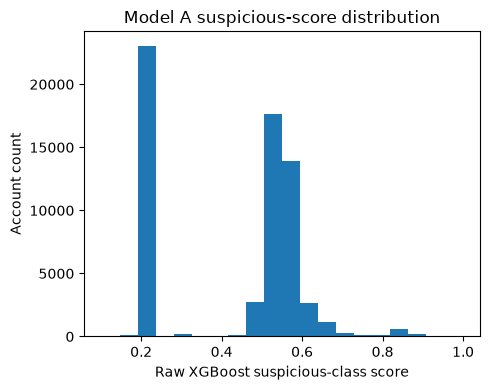

IBM AML is synthetic multi-agent simulation data; outputs are not real MSME validation.


In [12]:
# Visualize raw suspicious-class scores; no calibration is applied.
plt.figure(figsize=(5,4))
plt.hist(p_test,bins=20)
plt.xlabel('Raw XGBoost suspicious-class score')
plt.ylabel('Account count')
plt.title('Model A suspicious-score distribution')
plt.tight_layout()
plt.show()
print('IBM AML is synthetic multi-agent simulation data; outputs are not real MSME validation.')


## Save Model A artifacts

In [13]:
artifact={'model':'authenticity','model_version':'auth-v2-tuned','feature_schema_version':SCHEMA,'feature_names':FEATURES,'imputer':imputer,'model_estimator':model,'decision_threshold':f1_threshold,'selected_candidate':selected_name,'label_definition':'y_auth=0 if account appears as participant in any laundering-labeled transaction; otherwise 1','thresholds':{'LOW_MAX':.40,'HIGH_MIN':.75},'training_seed':SEED,'provenance':'synthetic_ibm_aml_multi_agent_simulation','training_oversampling':'none','algorithm':selected_name,'probabilities_calibrated':False,'tuning':'RandomizedSearchCV, 10 iterations, 3-fold CV'}
joblib.dump(artifact,MODELS/'auth.joblib',compress=3)
mpath=MODELS/'meta.json'; meta=json.loads(mpath.read_text()) if mpath.exists() else {'feature_schema_version':SCHEMA}
meta.update({'auth_model_version':'auth-v2-tuned','auth_feature_names':FEATURES,'auth_thresholds':{'LOW_MAX':.40,'HIGH_MIN':.75},'auth_algorithm':selected_name,'auth_probabilities_calibrated':False,'auth_training_oversampling':'none','auth_tuning':'RandomizedSearchCV, 10 iterations, 3-fold CV','auth_metrics':metrics,'auth_data_version':'ibm-aml-hi-small','auth_provenance':'synthetic_ibm_aml_multi_agent_simulation','auth_trained_at':datetime.now(timezone.utc).isoformat()})
mpath.write_text(json.dumps(meta,indent=2),encoding='utf-8')
(REPORTS/'metrics_auth.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
card=f'''# Model card: Authenticity (auth-v2-tuned)\n\nDataset: IBM AML HI-Small, synthetic multi-agent transaction simulation. Algorithms tuned: XGBoost and Random Forest; selected candidate: {selected_name}. No SMOTE or other synthetic oversampling is used. RandomizedSearchCV performs 10 parameter samples per algorithm with three-fold training-only cross-validation using F1 scoring. The decision threshold is selected on validation data, and test metrics are in metrics_auth.json. Account-level stratified 70/15/15 split, seed 42. Raw scores are not calibrated. The model learns generator patterns and is not validated on Indian MSMEs or UPI.\n'''
(REPORTS/'model_card_auth.md').write_text(card,encoding='utf-8')
print('saved',MODELS/'auth.joblib',MODELS/'meta.json',REPORTS)

saved C:\Users\shash\Documents\ChatGPT\ZeroCibil\models\auth.joblib C:\Users\shash\Documents\ChatGPT\ZeroCibil\models\meta.json C:\Users\shash\Documents\ChatGPT\ZeroCibil\reports
